# 07 · Classification: can wearable signals tell the three states apart, in people never seen before?

Only now, after notebooks 01–06, is machine learning used. The goal is **not** a headline accuracy. It is to answer:
1. How well can stress, aerobic and anaerobic states be separated **in unseen participants**?
2. Do combinations of signals beat single signals?
3. How much is physiology, and how much is just movement?

**Validation:** leave-one-subject-out (LOSO). Every participant is predicted by a model trained on the other
participants only. **Metrics:** macro-F1 and balanced accuracy (classes are imbalanced), per-class recall, confusion
matrices, and 95% CIs obtained by resampling participants.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
PROCESSED = ROOT / "data" / "processed"; INTERIM = ROOT / "data" / "interim"
C = P.COND_COLORS

import os; os.environ["PYTHONWARNINGS"] = "ignore"   # silence joblib-worker warnings
from sklearn.base import clone
from src.models import classify as K
from src.models.classify import CLASSES, FEATURE_SETS, FEATURE_LABELS

d = pd.read_csv(PROCESSED / "classification_windows.csv")
y, groups = d.target, d.subject_id
print(d.target.value_counts().to_string()); print("participants:", groups.nunique())
RESULTS = {}

target
AEROBIC      2401
ANAEROBIC     849
STRESS        668
participants: 36


## 1 · Why participant-grouped validation is non-negotiable

Same model (random forest, all signals), two validation schemes. In the random split, windows from the same
participant land in both training and test sets.

In [2]:
rf = K.make_models()["Random forest"]
leak = K.leakage_demo(rf, d[FEATURE_SETS["All signals"]], y, groups)
leak.to_csv(PROCESSED / "clf_leakage_demo.csv", index=False)
leak[["validation", "macro_f1", "balanced_accuracy", "accuracy"]].round(3)

,validation,macro_f1,balanced_accuracy,accuracy
0,Random 5-fold over windows (leaky),0.832,0.857,0.844
1,Leave-one-subject-out,0.659,0.691,0.669


With windows from the same people in training and test, macro-F1 is **0.83**. Evaluated on participants the
model has never seen, it drops to **0.66**. The ~0.17 gap is the model recognising *individuals* rather than states.
That is expected, given the ICCs of 0.8–0.99 for HR and EDA (notebook 06). The original paper reported 84% accuracy for
a four-class problem using 10-fold cross-validation over segments. This comparison shows why such figures should not be
read as performance on new people.

## 2 · Model comparison (all signals, LOSO)

In [3]:
rows, preds = [], {}
X = d[FEATURE_SETS["All signals"]]
for name, model in K.make_models().items():
    p = K.cv_predict(model, X, y, groups)
    preds[name] = p
    rows.append(dict(model=name, **K.scores(y, p), **K.participant_bootstrap(y, p, groups)))
models = pd.DataFrame(rows); models.to_csv(PROCESSED / "clf_models.csv", index=False)
models[["model", "macro_f1", "macro_f1_low", "macro_f1_high", "balanced_accuracy", "bal_acc_low", "bal_acc_high",
        "recall_STRESS", "recall_AEROBIC", "recall_ANAEROBIC"]].round(3)

,model,macro_f1,macro_f1_low,macro_f1_high,balanced_accuracy,bal_acc_low,bal_acc_high,recall_STRESS,recall_AEROBIC,recall_ANAEROBIC
0,Logistic regression,0.625,0.566,0.690,0.690,0.631,0.746,0.864,0.539,0.668
1,Decision tree (depth 4),0.577,0.526,0.628,0.639,0.590,0.688,0.778,0.449,0.689
2,Random forest,0.659,0.610,0.707,0.691,0.645,0.733,0.834,0.653,0.584
3,Gradient boosting,0.657,0.605,0.709,0.679,0.630,0.724,0.826,0.678,0.531


On unseen participants, the random forest and gradient boosting reach **macro-F1 ≈ 0.66** (95% CI 0.61–0.71) and
balanced accuracy ≈ 0.68–0.69. Logistic regression is close behind (0.63). The more flexible models give only a small,
overlapping gain over a linear model, so extra complexity is not clearly justified. `STRESS` is recognised best
(recall 0.83–0.86). `AEROBIC` and `ANAEROBIC` are confused with each other.

## 3 · Which signals carry the information? (modality ablation, random forest, LOSO)

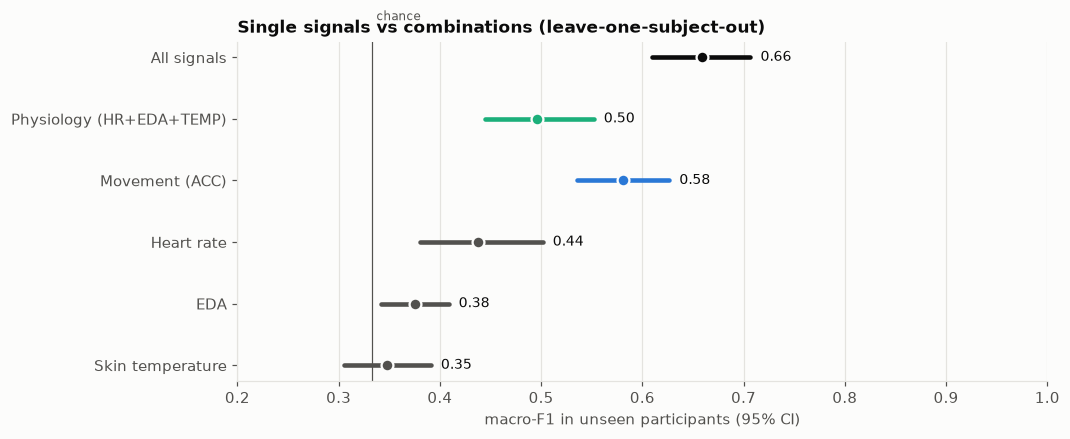

,feature_set,macro_f1,macro_f1_low,macro_f1_high,balanced_accuracy,recall_STRESS,recall_AEROBIC,recall_ANAEROBIC
0,Movement (ACC),0.581,0.535,0.627,0.606,0.834,0.594,0.391
1,Heart rate,0.437,0.380,0.501,0.550,0.449,0.258,0.943
2,EDA,0.375,0.342,0.409,0.405,0.395,0.409,0.411
3,Skin temperature,0.348,0.306,0.391,0.377,0.334,0.373,0.424
4,Physiology (HR+EDA+TEMP),0.496,0.445,0.552,0.547,0.557,0.469,0.616
5,All signals,0.659,0.610,0.707,0.691,0.834,0.653,0.584


In [4]:
abl_rows, abl_preds = [], {}
for set_name, cols in FEATURE_SETS.items():
    p = K.cv_predict(rf, d[cols], y, groups)
    abl_preds[set_name] = p
    abl_rows.append(dict(feature_set=set_name, n_features=len(cols), **K.scores(y, p), **K.participant_bootstrap(y, p, groups)))
abl = pd.DataFrame(abl_rows); abl.to_csv(PROCESSED / "clf_ablation.csv", index=False)

order = ["Skin temperature", "EDA", "Heart rate", "Movement (ACC)", "Physiology (HR+EDA+TEMP)", "All signals"]
a = abl.set_index("feature_set").reindex(order)
fig, ax = plt.subplots(figsize=(9.5, 4))
cols = [P.TEXT_2, P.TEXT_2, P.TEXT_2, C["AEROBIC"], C["STRESS"], P.TEXT]
for i, (s, r) in enumerate(a.iterrows()):
    ax.plot([r.macro_f1_low, r.macro_f1_high], [i, i], color=cols[i], lw=3, solid_capstyle="round")
    ax.scatter(r.macro_f1, i, s=60, color=cols[i], zorder=3, edgecolor=P.SURFACE, lw=1.5)
    ax.text(r.macro_f1_high + 0.01, i, f"{r.macro_f1:.2f}", va="center", fontsize=9, color=P.TEXT)
ax.axvline(1 / 3, color=P.TEXT_2, lw=0.8); ax.text(1 / 3, len(order) - 0.4, " chance", fontsize=8, color=P.TEXT_2)
ax.set_yticks(range(len(order)), order); ax.set_xlim(0.2, 1.0); ax.set_xlabel("macro-F1 in unseen participants (95% CI)")
ax.grid(axis="y", visible=False); ax.set_title("Single signals vs combinations (leave-one-subject-out)", loc="left")
P.save(fig, "07_ablation"); plt.show()
abl[["feature_set", "macro_f1", "macro_f1_low", "macro_f1_high", "balanced_accuracy", "recall_STRESS", "recall_AEROBIC", "recall_ANAEROBIC"]].round(3)

- **Combinations beat single signals:** all signals (0.66) > movement alone (0.58) > HR (0.44) > EDA (0.38) ≈ skin
  temperature (0.35, chance = 0.33).
- **Movement is the strongest single modality** for this three-class problem. That is expected: seated stress vs
  pedalling is largely a movement contrast.
- **Physiology alone (0.50)** is clearly above chance, but weaker than movement.
- EDA and skin temperature on their own barely separate the classes once different people have to be generalised to,
  consistent with their strong individuality (EDA ICC ≈ 0.9) and weak effects (temperature).

## 4 · Where the errors are

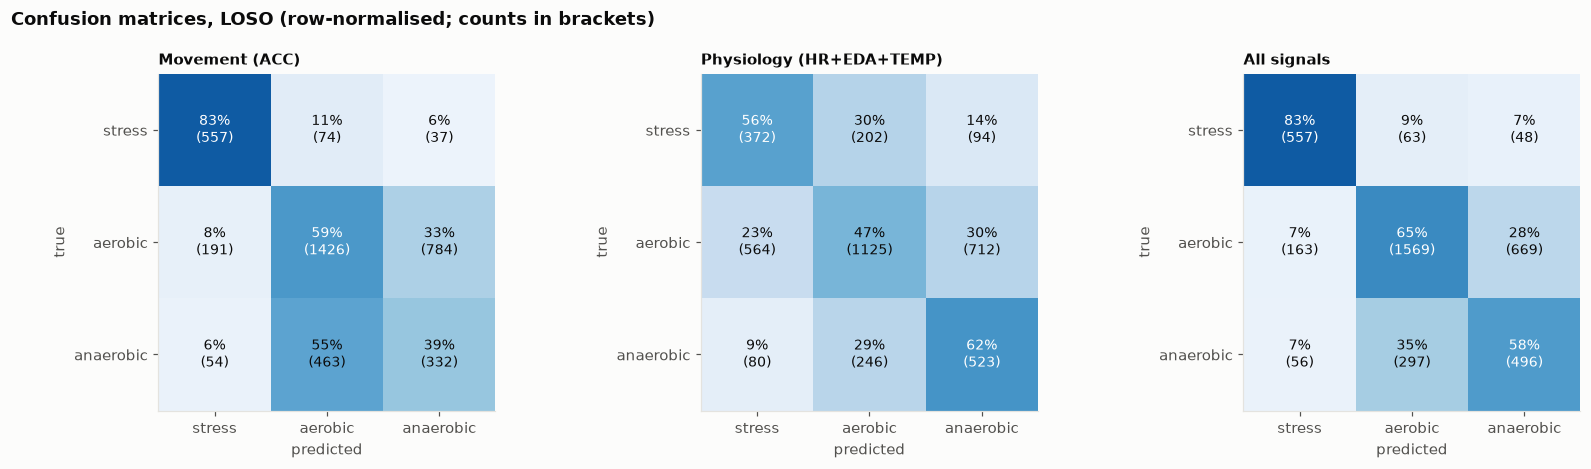

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, name in zip(axes, ["Movement (ACC)", "Physiology (HR+EDA+TEMP)", "All signals"]):
    cm = K.confusion(y, abl_preds[name]); cmn = cm.div(cm.sum(axis=1), axis=0)
    ax.imshow(cmn.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn.iloc[i, j]:.0%}\n({cm.iloc[i, j]})", ha="center", va="center", fontsize=9,
                    color="white" if cmn.iloc[i, j] > 0.55 else P.TEXT)
    ax.set_xticks(range(3), [c.lower() for c in CLASSES]); ax.set_yticks(range(3), [c.lower() for c in CLASSES])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(name, loc="left", fontsize=10)
fig.suptitle("Confusion matrices, LOSO (row-normalised; counts in brackets)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "07_confusion"); plt.show()

In [6]:
# Per-participant performance (all signals): who is hard to classify?
pp = pd.DataFrame(dict(y=y, p=abl_preds["All signals"], g=groups, cohort=d.cohort))
from sklearn.metrics import balanced_accuracy_score
per = pp.groupby("g").apply(lambda t: pd.Series(dict(bal_acc=balanced_accuracy_score(t.y, t.p) if t.y.nunique() > 1 else np.nan,
                                                    n_classes=t.y.nunique(), cohort=t.cohort.iloc[0])), include_groups=False)
per3 = per[per.n_classes == 3]
print(f"Participants with all three classes: {len(per3)}; per-participant balanced accuracy median {per3.bal_acc.median():.2f} "
      f"(IQR {per3.bal_acc.quantile(.25):.2f}-{per3.bal_acc.quantile(.75):.2f}), min {per3.bal_acc.min():.2f}")
print(per3.groupby("cohort").bal_acc.median().round(2).to_string())

Participants with all three classes: 30; per-participant balanced accuracy median 0.70 (IQR 0.58-0.78), min 0.45
cohort
V1   0.740
V2   0.680


- With movement only, `STRESS` is well recognised (83%), but aerobic and anaerobic windows are heavily confused (55% of
  anaerobic windows predicted as aerobic). Pedalling is pedalling.
- With physiology only, the errors are spread across all classes. Stress windows are often mistaken for aerobic ones
  (30%), consistent with the overlap in HR and EDA between moderate cycling and an acute stressor.
- With all signals, stress is separated well, and the remaining error is aerobic ↔ anaerobic (28% / 35%).
- Per participant, balanced accuracy has a median of 0.70 (IQR 0.58–0.78), ranging from 0.45 to near-perfect. Some
  people are much harder to classify than others. Performance is similar across cohorts (V1 0.74, V2 0.68).

## 5 · What the model relies on

Permutation importance = drop in macro-F1 on **held-out participants** when one feature is shuffled (GroupKFold,
5 folds × 10 repeats). Correlated features share credit (notebook 05), so read it by modality. Importance describes the
model, **not** physiological causation.

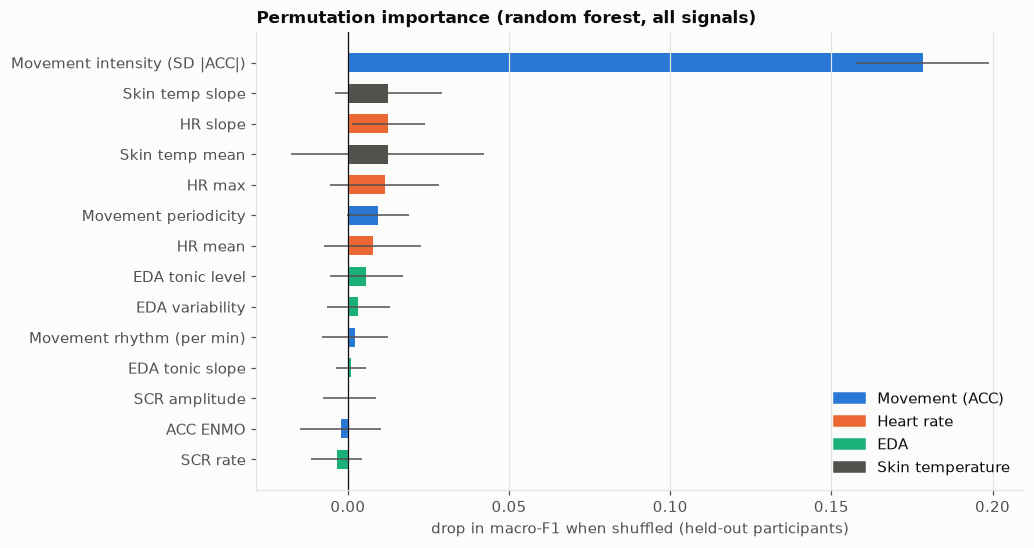

modality
Movement (ACC)     0.188
Heart rate         0.032
Skin temperature   0.025
EDA                0.007
Name: mean, dtype: float64

In [7]:
imp = K.grouped_permutation_importance(rf, d[FEATURE_SETS["All signals"]], y, groups)
imp.to_csv(PROCESSED / "clf_permutation_importance.csv", index=False)
mod_of = {f: k for k in ["Movement (ACC)", "Heart rate", "EDA", "Skin temperature"] for f in FEATURE_SETS[k]}
mcol = {"Movement (ACC)": C["AEROBIC"], "Heart rate": C["ANAEROBIC"], "EDA": C["STRESS"], "Skin temperature": P.TEXT_2}
imp = imp.sort_values("mean")
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.barh(range(len(imp)), imp["mean"], xerr=imp["std"], color=[mcol[mod_of[f]] for f in imp.feature], height=0.62,
        error_kw=dict(ecolor=P.TEXT_2, lw=1))
ax.set_yticks(range(len(imp)), [FEATURE_LABELS[f] for f in imp.feature]); ax.axvline(0, color=P.TEXT, lw=0.8)
ax.set_xlabel("drop in macro-F1 when shuffled (held-out participants)"); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in mcol.values()]
ax.legend(handles, mcol.keys(), loc="lower right"); ax.set_title("Permutation importance (random forest, all signals)", loc="left")
P.save(fig, "07_permutation_importance"); plt.show()
imp.sort_values("mean", ascending=False).assign(modality=lambda t: t.feature.map(mod_of)).groupby("modality")["mean"].sum().sort_values(ascending=False).round(3)

Movement intensity dominates (≈ 0.18 drop in macro-F1 when shuffled). Every physiological feature contributes
≤ 0.013 individually, partly because correlated features share credit and partly because of the shortcut examined in
5b. In the decision tree, the first split is movement intensity: low movement means seated, which means stress. Among
pedalling windows, the next split is whether HR is available: missing HR points to the anaerobic class.

### An interpretable rule set

A depth-3 decision tree fitted on all windows (for *interpretation* only; its LOSO performance is in section 2 as
the depth-4 tree). An explicit **"HR available"** variable is added, so that a split on missing HR is visible rather
than hidden behind the imputed median value.

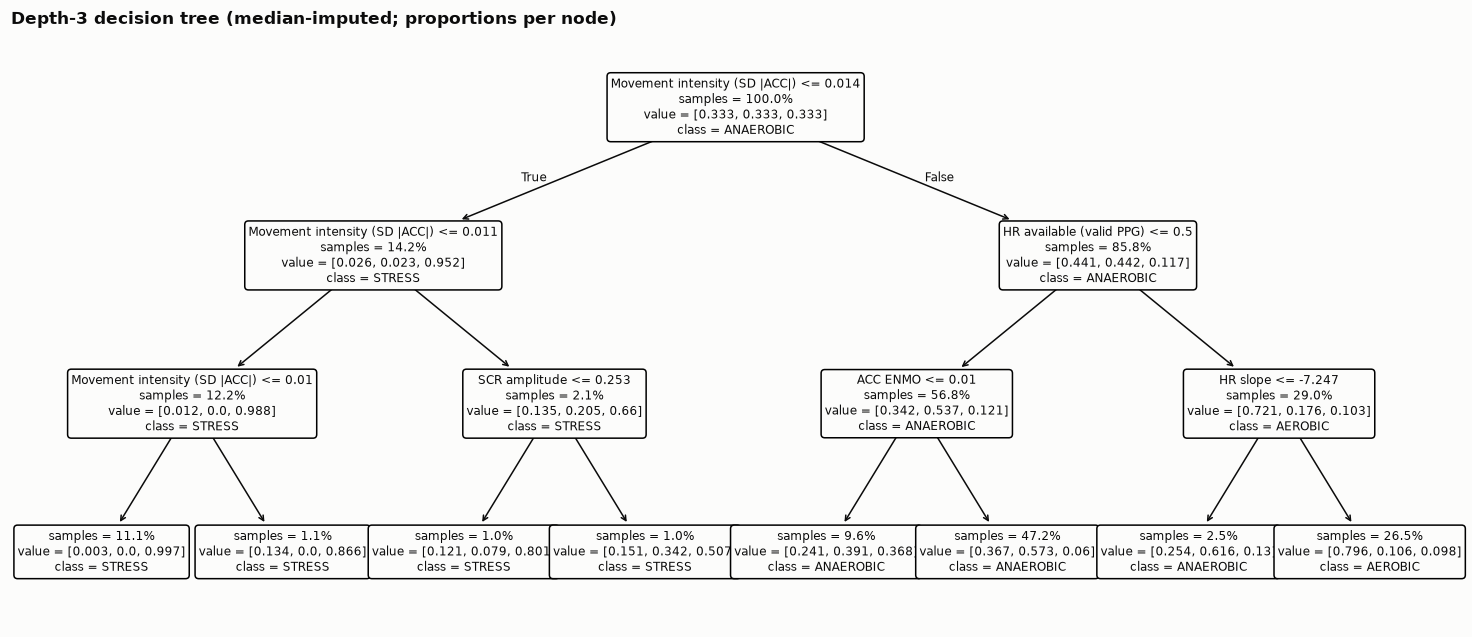

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
Xi = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=X.columns)
Xi["hr_available"] = d.hr_mean.notna().astype(int).to_numpy()   # make the missingness explicit
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, class_weight="balanced", random_state=0).fit(Xi, y)
fig, ax = plt.subplots(figsize=(17, 7))
names = [FEATURE_LABELS.get(c, "HR available (valid PPG)") for c in Xi.columns]
plot_tree(tree, feature_names=names, class_names=list(tree.classes_), filled=False,
          impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree (median-imputed; proportions per node)", loc="left")
P.save(fig, "07_decision_tree"); plt.show()

### 5b · A sensor-failure shortcut

HR is missing in 89% of `ANAEROBIC` windows (PPG failure during and after sprints), 57% of `AEROBIC` and 43% of
`STRESS` windows (notebook 05). How much of the "physiology" contribution is just this missingness pattern?

In [9]:
d["hr_missing"] = d.hr_mean.isna().astype(float)
short_rows = []
for name, cols in [("HR-missing indicator only", ["hr_missing"]),
                   ("Movement (ACC)", FEATURE_SETS["Movement (ACC)"]),
                   ("Movement + HR-missing indicator", FEATURE_SETS["Movement (ACC)"] + ["hr_missing"]),
                   ("All signals without HR", FEATURE_SETS["Movement (ACC)"] + FEATURE_SETS["EDA"] + FEATURE_SETS["Skin temperature"]),
                   ("All signals", FEATURE_SETS["All signals"])]:
    p = K.cv_predict(rf, d[cols], y, groups)
    short_rows.append(dict(feature_set=name, **K.scores(y, p)))
shortcut = pd.DataFrame(short_rows); shortcut.to_csv(PROCESSED / "clf_missingness_shortcut.csv", index=False)
shortcut[["feature_set", "macro_f1", "balanced_accuracy", "recall_STRESS", "recall_AEROBIC", "recall_ANAEROBIC"]].round(3)

,feature_set,macro_f1,balanced_accuracy,recall_STRESS,recall_AEROBIC,recall_ANAEROBIC
0,HR-missing indicator only,0.272,0.489,0.572,0.000,0.894
1,Movement (ACC),0.581,0.606,0.834,0.594,0.391
2,Movement + HR-missing indicator,0.639,0.675,0.831,0.606,0.589
3,All signals without HR,0.603,0.624,0.826,0.644,0.400
4,All signals,0.659,0.691,0.834,0.653,0.584


**This is the most important caveat of the classification.** Movement plus a single binary "HR missing" indicator
(0.64) gets almost as far as all signals together (0.66). Removing the HR features lowers macro-F1 to 0.60, mainly
because anaerobic recall drops. So most of what HR "adds" to the three-class problem is **the fact that the wrist PPG
fails during sprints**, not the heart-rate values themselves. Valid HR values add only about +0.02 beyond movement and
that failure pattern.

This is not a bug to hide. It is how a wearable classifier would behave in practice, and it shows exactly why
feature importance must not be read as physiology.

## 6 · The physiology-only test: stress task vs seated rest

In the three-class problem, movement does much of the work. Here movement is useless by design: both classes are
seated (stress tasks vs seated baseline and recovery, all from the same session). Can **physiology alone** detect acute
stress in an unseen person?

In [10]:
from src.signals.quality import masked_features
w = masked_features(pd.read_csv(PROCESSED / "windows.csv"))
s2 = w[w.analysis_state.isin(["REST_SEATED", "STRESS_RECOVERY", "STRESS_TMCT", "STRESS_SHORT"])].copy()
s2["target"] = np.where(s2.analysis_state.str.startswith("STRESS_T") | (s2.analysis_state == "STRESS_SHORT"), "STRESS", "REST")
y2, g2 = s2.target, s2.subject_id
print(y2.value_counts().to_string())
rows2 = []
for set_name in ["Movement (ACC)", "Heart rate", "EDA", "Physiology (HR+EDA+TEMP)", "All signals"]:
    for mname in ["Logistic regression", "Random forest"]:
        model = K.make_models()[mname]
        p = K.cv_predict(model, s2[FEATURE_SETS[set_name]], y2, g2)
        sc = K.scores(y2, p, labels=["REST", "STRESS"])
        rows2.append(dict(feature_set=set_name, model=mname, macro_f1=sc["macro_f1"], balanced_accuracy=sc["balanced_accuracy"],
                          recall_STRESS=sc["recall_STRESS"], recall_REST=sc["recall_REST"],
                          **K.participant_bootstrap(y2, p, g2, labels=["REST", "STRESS"])))
stress_rest = pd.DataFrame(rows2); stress_rest.to_csv(PROCESSED / "clf_stress_vs_rest.csv", index=False)
stress_rest.round(3)

target
REST      2556
STRESS     668


,feature_set,model,macro_f1,balanced_accuracy,recall_STRESS,recall_REST,macro_f1_low,macro_f1_high,bal_acc_low,bal_acc_high
0,Movement (ACC),Logistic regression,0.444,0.510,0.567,0.452,0.412,0.477,0.484,0.535
1,Movement (ACC),Random forest,0.573,0.591,0.445,0.737,0.551,0.594,0.564,0.616
2,Heart rate,Logistic regression,0.501,0.605,0.744,0.467,0.426,0.581,0.543,0.675
3,Heart rate,Random forest,0.501,0.592,0.699,0.485,0.441,0.559,0.538,0.647
4,EDA,Logistic regression,0.612,0.617,0.418,0.816,0.550,0.671,0.564,0.671
5,EDA,Random forest,0.608,0.636,0.531,0.740,0.564,0.652,0.597,0.675
6,Physiology (HR+EDA+TEMP),Logistic regression,0.586,0.673,0.750,0.596,0.516,0.665,0.614,0.738
7,Physiology (HR+EDA+TEMP),Random forest,0.650,0.683,0.602,0.764,0.603,0.702,0.641,0.733
8,All signals,Logistic regression,0.593,0.667,0.708,0.625,0.523,0.667,0.611,0.729
9,All signals,Random forest,0.672,0.701,0.609,0.793,0.618,0.728,0.656,0.751


With movement offering little (both classes are seated):
- **Physiology alone detects acute stress in unseen people: macro-F1 0.65** (CI 0.60–0.70), balanced accuracy 0.68
  (random forest).
- **EDA is the most informative single signal** (macro-F1 ≈ 0.61). HR alone gives 0.50, but with high stress
  recall (0.70–0.74).
- Movement alone reaches 0.57: participants sit *stiller* during tasks, and the short tasks involve speaking.
- Adding movement to physiology raises macro-F1 only slightly (0.67).

So in the seated stress setting, where movement cannot do the job, the wearable's physiological channels carry real,
generalisable information. It is modest: about 2 in 3 windows are correctly attributed in a new person.

## Summary

| Question | Answer (unseen participants, LOSO) |
|---|---|
| Can the three states be separated? | Moderately: **macro-F1 0.66** (0.61–0.71), balanced accuracy 0.69 |
| Leaky window-level validation | Would have reported 0.83: inflated by participant identity |
| Do combinations beat single signals? | Yes: all signals 0.66 vs best single modality (movement) 0.58 |
| Is it physiology or movement? | **Mostly movement plus a sensor-failure pattern** in the 3-class problem. Physiological values add little there |
| Where does physiology matter? | **Stress vs seated rest:** physiology alone 0.65, EDA the strongest single signal |
| Hardest distinction | Aerobic vs anaerobic cycling (both pedalling, similar session-level physiology) |

This is not "AI identifies stress and exercise with high accuracy". A wrist wearable separates seated stress from
cycling mostly by movement. It detects acute stress during sitting from physiology with modest accuracy, and it
struggles to tell two kinds of cycling apart. All of this is evaluated on people the model has never seen.